# Chapter 13: A Variable Is a Name

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will watch a letter stand in for a number, see why grouping changes an answer, learn which terms may be combined, see why multiplying two sums needs four pieces, and split a price rule into a fixed part and a changing part.

**A note on the code.** The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to experiment, change a number in a cell and run it again.

## Setup

This one cell loads two common tools, numpy (for lists of numbers) and matplotlib (for pictures), and a few small helpers that tidy the output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

TEAL, NAVY, GOLD, RED, GREY = "#0f6268", "#172a3b", "#b8860b", "#b5472f", "#8a949a"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def finish(fig):
    """Tidy the layout and show the picture."""
    fig.tight_layout()
    plt.show()

def q(v):
    """Write a Fraction the way we would by hand: 3/2, or 5 when whole."""
    v = Fraction(v)
    return str(v.numerator) if v.denominator == 1 else f"{v.numerator}/{v.denominator}"

def par(v):
    """Wrap negative numbers in parentheses, the way we do when substituting."""
    s = q(v)
    return f"({s})" if Fraction(v) < 0 else s

## 1. Add two, then triple

**The question:** Why do $3(n + 2)$ and $3n + 2$ give different answers from the same starting number?

**The equations from the chapter:**

$$3(n + 2) \qquad\qquad 3n + 2$$

**What the symbols mean:** $n$ is a name for the starting value (here a whole number, 0 or more). The 3 and the 2 are fixed numbers. Writing the 3 right next to the parentheses means "3 times the whole group inside".

Predict first: at $n = 4$ the chapter gets 18 from one instruction and 14 from the other. Will the gap still be 4 at $n = 0$?

In [2]:
n = 4

print("Instruction 1: add 2 first, then triple, written 3(n + 2)")
print(f"  add 2:   n + 2 = {n} + 2 = {n + 2}")
print(f"  triple:  3 x {n + 2} = {3 * (n + 2)}")
print()
print("Instruction 2: triple first, then add 2, written 3n + 2")
print(f"  triple:  3 x n = 3 x {n} = {3 * n}")
print(f"  add 2:   {3 * n} + 2 = {3 * n + 2}")
print()
print(f"Gap: {3 * (n + 2)} - {3 * n + 2} = {3 * (n + 2) - (3 * n + 2)}")
print()
print("The same two instructions at the other starting values:")
for m in (0, 1, 4):
    a, b = 3 * (m + 2), 3 * m + 2
    print(f"  n = {m}: 3({m} + 2) = 3 x {m + 2} = {a};  3({m}) + 2 = {3 * m} + 2 = {b};  gap = {a} - {b} = {a - b}")

Instruction 1: add 2 first, then triple, written 3(n + 2)
  add 2:   n + 2 = 4 + 2 = 6
  triple:  3 x 6 = 18

Instruction 2: triple first, then add 2, written 3n + 2
  triple:  3 x n = 3 x 4 = 12
  add 2:   12 + 2 = 14

Gap: 18 - 14 = 4

The same two instructions at the other starting values:
  n = 0: 3(0 + 2) = 3 x 2 = 6;  3(0) + 2 = 0 + 2 = 2;  gap = 6 - 2 = 4
  n = 1: 3(1 + 2) = 3 x 3 = 9;  3(1) + 2 = 3 + 2 = 5;  gap = 9 - 5 = 4
  n = 4: 3(4 + 2) = 3 x 6 = 18;  3(4) + 2 = 12 + 2 = 14;  gap = 18 - 14 = 4


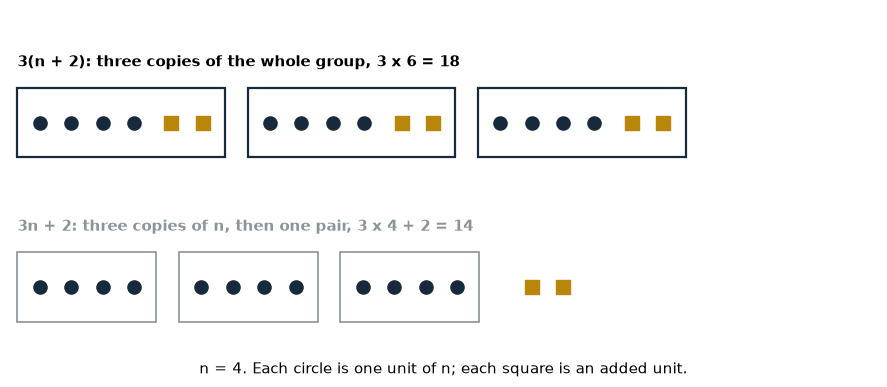

In [3]:
def dots(ax, x, y, k, marker, color):
    xs = [x + 0.3 + i * 0.42 for i in range(k)]
    if k:
        ax.scatter(xs, [y] * k, s=90, marker=marker, color=color, zorder=3)
    return x + 0.3 + max(k - 1, 0) * 0.42 + 0.3

n = 4
fig, ax = plt.subplots(figsize=(9, 4))
# Top row: 3(n + 2), three copies of the whole group (n circles and 2 squares)
x = 0.1
for g in range(3):
    start = x
    x = dots(ax, x, 2.7, n, "o", NAVY)
    x = dots(ax, x - 0.1, 2.7, 2, "s", GOLD)
    ax.add_patch(plt.Rectangle((start, 2.3), x - start, 0.8, fill=False, edgecolor=NAVY, linewidth=1.6))
    x += 0.3
ax.text(0.1, 3.35, f"3(n + 2): three copies of the whole group, 3 x {n + 2} = {3 * (n + 2)}", fontweight="bold")
# Bottom row: 3n + 2, three copies of n, then one pair
x = 0.1
for g in range(3):
    start = x
    x = dots(ax, x, 0.8, n, "o", NAVY)
    ax.add_patch(plt.Rectangle((start, 0.4), x - start, 0.8, fill=False, edgecolor=GREY, linewidth=1.2))
    x += 0.3
dots(ax, x + 0.1, 0.8, 2, "s", GOLD)
ax.text(0.1, 1.45, f"3n + 2: three copies of n, then one pair, 3 x {n} + 2 = {3 * n + 2}", fontweight="bold", color=GREY)
ax.set_xlim(0, 11.6); ax.set_ylim(0, 4)
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel(f"n = {n}. Each circle is one unit of n; each square is an added unit.")
finish(fig)

**What this shows.** In the top row the "plus 2" sits inside the group, so it gets copied three times: six added squares. In the bottom row only $n$ is copied; the 2 is added once. The gap of $18 - 14 = 4$ is exactly the four extra squares, and it does not depend on $n$.

**Where it stops working.** Here $n$ is a whole number from 0 up, like the chapter's rule. The habit that matters is wider: when you turn words into symbols, read them back aloud. If "then triple" applies to the whole result, it needs parentheses.

## 2. Which terms can combine

**The question:** When does a shorter expression really name the same quantity as a longer one?

**The equations from the chapter:**

$$4x + 3 - 2x + 5 = 2x + 8 \qquad\qquad 4x - 2x = (4 - 2)x$$

**What the symbols mean:** A *term* is a signed piece separated by plus or minus. In $4x$ the *coefficient* is 4. *Like terms* have the same variable part, so $4x$ and $-2x$ combine. But $2x$ and $3x^2$ do not.

Predict first: at $x = 3$ with the unlike pair $2x + 3x^2$, will either shortcut ($5x$ or $5x^2$) match?

In [4]:
x = 3
print(f"LIKE TERMS at x = {x}")
a = 4 * x + 3 - 2 * x + 5
print(f"  original: 4x + 3 - 2x + 5 = 4 x {x} + 3 - 2 x {x} + 5 = {4 * x} + 3 - {2 * x} + 5 = {a}")
b = 2 * x + 8
print(f"  shorter:  2x + 8 = 2 x {x} + 8 = {2 * x} + 8 = {b}")
print(f"  match? {a == b}")
print()
print(f"UNLIKE TERMS at x = {x}")
o = 2 * x + 3 * x ** 2
print(f"  original: 2x + 3x^2 = 2 x {x} + 3 x {x ** 2} = {2 * x} + {3 * x ** 2} = {o}")
print(f"  proposal 5x:   5 x {x} = {5 * x}   matches? {5 * x == o}")
print(f"  proposal 5x^2: 5 x {x}^2 = 5 x {x ** 2} = {5 * x ** 2}   matches? {5 * x ** 2 == o}")
print()
print("Same tests at other inputs (original / proposals):")
for v in (-2, 0, 2, 3):
    pv = par(v)
    print(f"  x = {v:>2}: like: {4*v+3-2*v+5} vs {2*v+8};   unlike: {2*v+3*v*v} vs {5*v} vs {5*v*v}")
print()
print("At x = 0 all three unlike forms give 0, so a lucky input can hide a wrong shortcut.")

LIKE TERMS at x = 3
  original: 4x + 3 - 2x + 5 = 4 x 3 + 3 - 2 x 3 + 5 = 12 + 3 - 6 + 5 = 14
  shorter:  2x + 8 = 2 x 3 + 8 = 6 + 8 = 14
  match? True

UNLIKE TERMS at x = 3
  original: 2x + 3x^2 = 2 x 3 + 3 x 9 = 6 + 27 = 33
  proposal 5x:   5 x 3 = 15   matches? False
  proposal 5x^2: 5 x 3^2 = 5 x 9 = 45   matches? False

Same tests at other inputs (original / proposals):
  x = -2: like: 4 vs 4;   unlike: 8 vs -10 vs 20
  x =  0: like: 8 vs 8;   unlike: 0 vs 0 vs 0
  x =  2: like: 12 vs 12;   unlike: 16 vs 10 vs 20
  x =  3: like: 14 vs 14;   unlike: 33 vs 15 vs 45

At x = 0 all three unlike forms give 0, so a lucky input can hide a wrong shortcut.


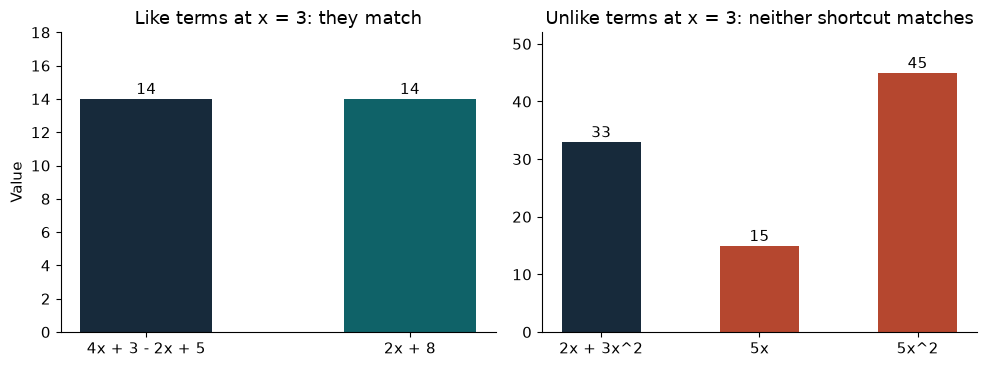

In [5]:
x = 3
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))

names = ["4x + 3 - 2x + 5", "2x + 8"]
vals = [4 * x + 3 - 2 * x + 5, 2 * x + 8]
a1.bar(names, vals, color=[NAVY, TEAL], width=0.5)
for i, v in enumerate(vals):
    a1.text(i, v + 0.3, str(v), ha="center")
a1.set_title(f"Like terms at x = {x}: they match")
a1.set_ylim(0, 18); a1.set_ylabel("Value")

names = ["2x + 3x^2", "5x", "5x^2"]
vals = [2 * x + 3 * x ** 2, 5 * x, 5 * x ** 2]
a2.bar(names, vals, color=[NAVY, RED, RED], width=0.5)
for i, v in enumerate(vals):
    a2.text(i, v + 0.8, str(v), ha="center")
a2.set_title(f"Unlike terms at x = {x}: neither shortcut matches")
a2.set_ylim(0, 52)
finish(fig)

**What this shows.** Think of tiles: $x$ is a strip, $x^2$ is a big square, 1 is a small square. Two strips can be counted together, and a strip and a positive strip cancel a negative one. But a strip never turns into a big square, so $2x$ and $3x^2$ cannot merge into one term.

**Where it stops working.** A matching check is only a check. At $x = 0$ every wrong shortcut above gives 0 and looks right. One mismatch proves a mistake; one match does not prove you are correct. The real reason like terms combine is distribution: $4x - 2x = (4 - 2)x = 2x$.

## 3. Four regions in one rectangle

**The question:** Why does $(x + 2)(x + 5)$ have a middle term $7x$, and what does $x^2 + 10$ leave out?

**The equations from the chapter:**

$$(x + 2)(x + 5) \qquad\qquad x^2 + 7x + 10 \qquad\qquad x^2 + 10$$

**What the symbols mean:** Picture a rectangle with width $x + 5$ and height $x + 2$. Each of its four regions is one width piece times one height piece.

Predict first: at $x = 1$, how much area does $x^2 + 10$ lose compared with the whole rectangle?

In [6]:
x = 1
w, h = x + 5, x + 2
print(f"width  = x + 5 = {x} + 5 = {w}")
print(f"height = x + 2 = {x} + 2 = {h}")
print(f"whole rectangle: (x + 2)(x + 5) = {h} x {w} = {h * w}")
print()
print("Four regions (height piece x width piece):")
print(f"  x by x : x^2 = {x} x {x} = {x * x}")
print(f"  x by 5 : 5x  = 5 x {x} = {5 * x}")
print(f"  2 by x : 2x  = 2 x {x} = {2 * x}")
print(f"  2 by 5 : 10")
print(f"sum of regions: {x * x} + {5 * x} + {2 * x} + 10 = {x * x + 5 * x + 2 * x + 10}")
print(f"combined form:  x^2 + 7x + 10 = {x * x} + {7 * x} + 10 = {x * x + 7 * x + 10}")
print()
short = x * x + 10
print(f"The proposal x^2 + 10 = {x * x} + 10 = {short}")
print(f"It misses the side strips: 5x + 2x = {5 * x} + {2 * x} = {7 * x}, and {short} + {7 * x} = {short + 7 * x}")
print()
print("Other lengths:")
for v in (1, 2, 3, 4):
    print(f"  x = {v}: (x + 2)(x + 5) = {v + 2} x {v + 5} = {(v + 2) * (v + 5)};  x^2 + 10 = {v * v + 10};  missing 7x = {7 * v}")

width  = x + 5 = 1 + 5 = 6
height = x + 2 = 1 + 2 = 3
whole rectangle: (x + 2)(x + 5) = 3 x 6 = 18

Four regions (height piece x width piece):
  x by x : x^2 = 1 x 1 = 1
  x by 5 : 5x  = 5 x 1 = 5
  2 by x : 2x  = 2 x 1 = 2
  2 by 5 : 10
sum of regions: 1 + 5 + 2 + 10 = 18
combined form:  x^2 + 7x + 10 = 1 + 7 + 10 = 18

The proposal x^2 + 10 = 1 + 10 = 11
It misses the side strips: 5x + 2x = 5 + 2 = 7, and 11 + 7 = 18

Other lengths:
  x = 1: (x + 2)(x + 5) = 3 x 6 = 18;  x^2 + 10 = 11;  missing 7x = 7
  x = 2: (x + 2)(x + 5) = 4 x 7 = 28;  x^2 + 10 = 14;  missing 7x = 14
  x = 3: (x + 2)(x + 5) = 5 x 8 = 40;  x^2 + 10 = 19;  missing 7x = 21
  x = 4: (x + 2)(x + 5) = 6 x 9 = 54;  x^2 + 10 = 26;  missing 7x = 28


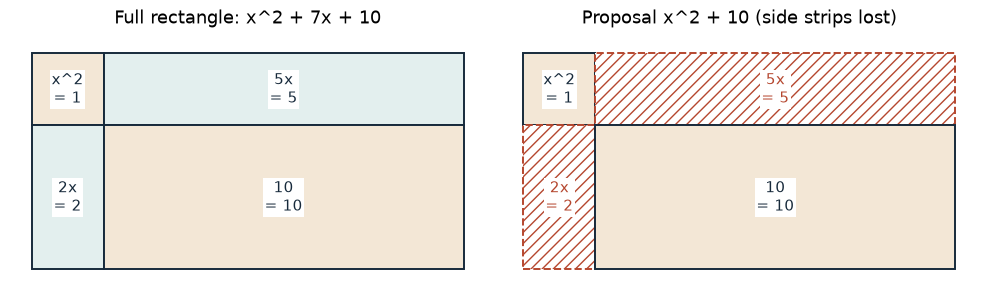

In [7]:
x = 1
w, h = x + 5, x + 2
regions = [  # left, bottom, width, height, label, area, is a side strip
    (0, 2, x, x, "x^2", x * x, False),
    (x, 2, 5, x, "5x", 5 * x, True),
    (0, 0, x, 2, "2x", 2 * x, True),
    (x, 0, 5, 2, "10", 10, False),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, drop, title in [(axes[0], False, "Full rectangle: x^2 + 7x + 10"),
                        (axes[1], True, "Proposal x^2 + 10 (side strips lost)")]:
    for l, b, rw, rh, name, area, side in regions:
        lost = drop and side
        ax.add_patch(plt.Rectangle((l, b), rw, rh, facecolor="white" if lost else ("#e3efee" if side else "#f3e7d6"),
                                   edgecolor=RED if lost else NAVY, hatch="///" if lost else None,
                                   linewidth=1.4, linestyle="dashed" if lost else "solid"))
        ax.text(l + rw / 2, b + rh / 2, f"{name}\n= {area}", ha="center", va="center",
                color=RED if lost else NAVY, bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlim(-0.3, w + 0.3); ax.set_ylim(-0.3, h + 0.3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title)
finish(fig)

**What this shows.** Multiplying two sums means every piece of one group meets every piece of the other: four products before anything combines. The two side strips, $5x$ and $2x$, are the cross-products that join into $7x$. Drop them and the area falls short by $7x$.

**Where it stops working.** The rectangle picture needs a positive $x$ (a length). The algebra itself, distribution, is true for any number $x$. The shortcut $x^2 + 10$ fails at every positive $x$ because it always drops the $7x$.

## 4. A fixed fee and a rate

**The question:** In the chapter's example cost rule, which part stays put and which part moves with the count?

**The equations from the chapter:**

$$C(n) = \$4 + (\$1.50/\text{item})\,n \qquad\qquad C(6) = \$4 + \$9 = \$13$$

**What the symbols mean:** $n$ is the number of items (a whole number, 0 or more). \$4 is the fixed fee. \$1.50 per item is the rate. $C(n)$ is read "the cost at $n$"; the $C$ is a name, not something multiplied. This is an example service, not a real price.

Predict first: going from 2 items to 6 items, by how many dollars should the cost rise?

In [8]:
fee, rate = Fraction(4), Fraction(3, 2)

def cost(n):
    return fee + rate * n

n = 6
print(f"fixed term    = 4 dollars")
print(f"per-item term = 1.50 x {n} = {float(rate * n):g} dollars")
print(f"C({n}) = 4 + 1.50 x {n} = 4 + {float(rate * n):g} = {float(cost(n)):g} dollars")
print("With units: ($4) + ($1.50/item)(6 items) = $4 + $9 = $13, because the item units cancel.")
print()
print("Other counts:")
for k in (0, 2, 6):
    print(f"  C({k}) = 4 + 1.50 x {k} = 4 + {float(rate * k):g} = {float(cost(k)):g}")
print()
print(f"Rise from 2 items to 6 items: C(6) - C(2) = {float(cost(6)):g} - {float(cost(2)):g} = {float(cost(6) - cost(2)):g}")
print(f"Same thing from the rate alone: 1.50 x (6 - 2) = 1.50 x 4 = {float(rate * 4):g}")
print()
print(f"Pushing n = -3 through the symbols: 4 + 1.50 x (-3) = 4 - 4.50 = {float(cost(-3)):.2f}")
print("The arithmetic runs, but a count of items cannot be -3, so this is not a cost in the model.")

fixed term    = 4 dollars
per-item term = 1.50 x 6 = 9 dollars
C(6) = 4 + 1.50 x 6 = 4 + 9 = 13 dollars
With units: ($4) + ($1.50/item)(6 items) = $4 + $9 = $13, because the item units cancel.

Other counts:
  C(0) = 4 + 1.50 x 0 = 4 + 0 = 4
  C(2) = 4 + 1.50 x 2 = 4 + 3 = 7
  C(6) = 4 + 1.50 x 6 = 4 + 9 = 13

Rise from 2 items to 6 items: C(6) - C(2) = 13 - 7 = 6
Same thing from the rate alone: 1.50 x (6 - 2) = 1.50 x 4 = 6

Pushing n = -3 through the symbols: 4 + 1.50 x (-3) = 4 - 4.50 = -0.50
The arithmetic runs, but a count of items cannot be -3, so this is not a cost in the model.


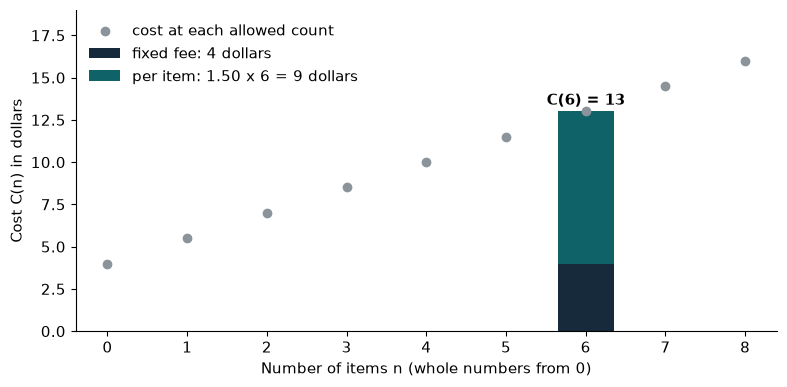

In [9]:
fee, rate, n = 4, 1.5, 6
ks = np.arange(0, 9)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(ks, fee + rate * ks, color=GREY, zorder=3, label="cost at each allowed count")
ax.bar([n], [fee], width=0.7, color=NAVY, label="fixed fee: 4 dollars")
ax.bar([n], [rate * n], bottom=[fee], width=0.7, color=TEAL, label=f"per item: 1.50 x {n} = {rate * n:g} dollars")
ax.text(n, fee + rate * n + 0.4, f"C({n}) = {fee + rate * n:g}", ha="center", fontweight="bold")
ax.set_xlabel("Number of items n (whole numbers from 0)")
ax.set_ylabel("Cost C(n) in dollars")
ax.set_ylim(0, 19)
ax.legend(loc="upper left", frameon=False)
finish(fig)

**What this shows.** The navy part is the fixed fee; it is the same at every count. The teal part is the rate times the count, and it is the only part that moves. Any price shaped like "a fixed amount plus so much per item" splits this way, and carrying the units (dollars per item times items leaves dollars) keeps you honest.

**Where it stops working.** The model only makes sense for counts 0, 1, 2, and so on. At $n = -3$ the symbols still give $-0.50$, but that answers a symbol question, not a model question.

## Practice

Try each one on paper first, then open the answer.

**1.** Using $n = 1$, what does each instruction, $3(n + 2)$ and $3n + 2$, give, and what is the gap?

<details><summary>Show answer</summary>

$3(1 + 2) = 3 \times 3 = 9$ and $3(1) + 2 = 3 + 2 = 5$. The gap is $9 - 5 = 4$, the same gap as at $n = 4$.

</details>

**2.** At $x = 3$, what do $2x + 3x^2$ and $5x$ give? Can you replace one with the other?

<details><summary>Show answer</summary>

$2x + 3x^2 = 2 \times 3 + 3 \times 9 = 6 + 27 = 33$, while $5x = 5 \times 3 = 15$. They differ, so $2x + 3x^2$ is not $5x$.

</details>

**3.** At $x = 2$, what is $(x + 2)(x + 5)$, and how much does $x^2 + 10$ miss?

<details><summary>Show answer</summary>

$(2 + 2)(2 + 5) = 4 \times 7 = 28$. The proposal gives $2^2 + 10 = 4 + 10 = 14$. It misses $5 \times 2 + 2 \times 2 = 10 + 4 = 14$, and $14 + 14 = 28$.

</details>